In [40]:
# imports
import pandas as pd
from sklearn.metrics import adjusted_mutual_info_score as AMI
import igraph as ig
import partition_igraph
import numpy as np
from collections import Counter
import matplotlib.pyplot as plt

### Chapter 5 Question 1

First, let's define a function to run all clustering coefficients, which has an option to exclude Girvan-Newman (might be useful for Question 2, since it might be too long to run) and to pass along ground-truth, since we only have it for karate club and not for GitHib ml graph:

In [9]:
def run_all_clustering_algorithms(g, GirvanNewman=True, ground_truth=None):
    results = {}

    # ECG
    partition = g.community_ecg().membership
    results['ECG'] = {'partition': partition, 'modularity': g.modularity(partition)}

    # Leiden
    partition = g.community_leiden(objective_function='modularity').membership
    results['Leiden'] = {'partition': partition, 'modularity': g.modularity(partition)}

    # Louvain
    partition = g.community_multilevel().membership
    results['Louvain'] = {'partition': partition, 'modularity': g.modularity(partition)}

    # Infomap
    partition = g.community_infomap().membership
    results['Infomap'] = {'partition': partition, 'modularity': g.modularity(partition)}

    # Label Propagation
    partition = g.community_label_propagation().membership
    results['Label Propagation'] = {'partition': partition, 'modularity': g.modularity(partition)}

    if GirvanNewman:
        gn = g.community_edge_betweenness()
        partition = gn.as_clustering(n=2).membership
        results['Girvan-Newman'] = {
            'partition': partition,
            'modularity': g.modularity(partition)
        }

    # CNM
    partition = g.community_fastgreedy().as_clustering().membership
    results['CNM'] = {'partition': partition, 'modularity': g.modularity(partition)}


    if ground_truth is not None:
        for name, data in results.items():
            data['ami'] = AMI(ground_truth, data['partition'])

    return results


Now, let's compare partitions produced by the algorithms on karate club graph:

In [10]:
g_zac = ig.Graph.Famous('zachary')
g_zac.vs['size'] = 14
g_zac.vs['label'] = g_zac.vs['name'] = [str(i) for i in range(g_zac.vcount())]
g_zac.vs['label_size'] = 8
g_zac.es['color'] = 'gainsboro'
g_zac.vs['comm'] = [0,0,0,0,0,0,0,0,1,1,0,0,0,0,1,1,0,0,1,0,1,0,1,1,1,1,1,1,1,1,1,1,1,1]

results = run_all_clustering_algorithms(g_zac, ground_truth=g_zac.vs['comm'])

for name, data in results.items():
    print(name, f": AMI = {data['ami']}, Modularity = {data['modularity']}")

ECG : AMI = 0.5065761372145331, Modularity = 0.3978468113083498
Leiden : AMI = 0.6711594278801386, Modularity = 0.4197896120973044
Louvain : AMI = 0.6711594278801386, Modularity = 0.4197896120973044
Infomap : AMI = 0.6874223479049212, Modularity = 0.40203813280736356
Label Propagation : AMI = 0.49312780025167535, Modularity = 0.36678172255095337
Girvan-Newman : AMI = 0.8327564079186137, Modularity = 0.3599605522682447
CNM : AMI = 0.6807645098886009, Modularity = 0.38067061143984227


The Girvan-Newman algorithm performed best in terms of AMI (0.833), suggesting that it found communities closest to the ground truth, while Label Propagation performed worst (0.493).
The Louvain and Leiden algorithms achieved the highest modularity scores (0.420), suggesting they found the most densely connected communities.

### Chapter 5 Question 2

First, let's build the ML developers subgrpah:

In [11]:
D = pd.read_csv('musae_git_edges.csv')
tuples = [tuple(x) for x in D.values]
gh = ig.Graph.TupleList(tuples, directed = False)
X = pd.read_csv('musae_git_target.csv')

idx = [int(i) for i in gh.vs['name']]
sorterIndex = dict(zip(idx,range(len(idx))))
X['Rank'] = X['id'].map(sorterIndex) 
X.sort_values(['Rank'], ascending=[True],inplace=True)
X.dropna(inplace=True)

lbl = ['web','ml']
gh.vs['lbl'] = [lbl[i] for i in list(X['ml_target'])]

gh_ml = gh.subgraph([v for v in gh.vs() if v['lbl']=='ml'])

Now, let's run partitioning algorithms on the graph (reusing the function from Question 1) and look at how they compare to each other (this time without Girvan-Newman, as it takes too long to finish computing):

In [13]:
# function to create a table with ami scores between partitionings obtained by each algorithm
def create_ami_table(results):
    algorithms = list(results.keys())
    n = len(algorithms)
    ami_table = np.zeros((n, n))
    
    for i in range(n):
        for j in range(n):
            ami_table[i,j] = AMI(results[algorithms[i]]['partition'], results[algorithms[j]]['partition'])
    
    return pd.DataFrame(ami_table, index=algorithms, columns=algorithms)


results_git_ml = run_all_clustering_algorithms(gh_ml, GirvanNewman=False)
ami_table_git = create_ami_table(results_git_ml)
ami_table_git

,ECG,Leiden,Louvain,Infomap,Label Propagation,CNM
ECG,1.000000,0.604771,0.602868,0.577266,0.484496,0.531452
Leiden,0.604771,1.000000,0.651755,0.502498,0.573524,0.594754
Louvain,0.602868,0.651755,1.000000,0.498379,0.574093,0.576488
Infomap,0.577266,0.502498,0.498379,1.000000,0.290345,0.463801
Label Propagation,0.484496,0.573524,0.574093,0.290345,1.000000,0.597009
CNM,0.531452,0.594754,0.576488,0.463801,0.597009,1.000000


Leiden and Louvain algorithms show the highest similarity to each other (AMI = 0.652), suggesting they find similar community structures. We can also see that Infomap and Label Propagation show the lowest agreement (AMI = 0.290), implying that they discover quite different community patterns in this network.

### Chapter 5 Question 5

First, let's load the ABCD graph:

In [17]:
from abcd_graph import ABCDGraph, ABCDParams

# Parameters for ABCD graph
n = 1000  # number of nodes
xi = 0.1   # noise parameter

# degrees
gamma = 2.5
delta = 5
Delta = 50

# communities
beta = 1.5
s = 75
S = 150

# Generate the graph
params = ABCDParams(vcount=n, gamma=gamma, min_degree=delta, max_degree=Delta, 
                    beta=beta, min_community_size=s, max_community_size=S, xi=xi)
g = ABCDGraph(params).build()
G = g.exporter.to_igraph()

Functions from Chapter 5 Notebook that compute z(v) and p(v) scores:

In [30]:
def nwmd(G, A):
    # within module degrees
    deg_in = [sum([A[v] == A[i] for i in G.neighbors(v)]) for v in range(G.vcount())]
    deg_in_mean = [ np.mean([deg_in[i] for i in range(G.vcount()) if A[i] == j]) for j in set(A) ]
    deg_in_std = [ np.std([deg_in[i] for i in range(G.vcount()) if A[i] == j], ddof=1) for j in set(A) ]
    return [ (deg_in[v]-deg_in_mean[A[v]]) / deg_in_std[A[v]] for v in range(G.vcount()) ]

def pc(G, A):
    deg = G.degree()
    coef = []
    for v in range(G.vcount()):
        coef.append(1-np.sum([(x/deg[v])**2 for x in Counter([A[i] for i in G.neighbors(v)]).values()]))
    return coef

Now, let's compute and plot the z(v) and p(v) scores for all nodes as was done for the karate club graph:

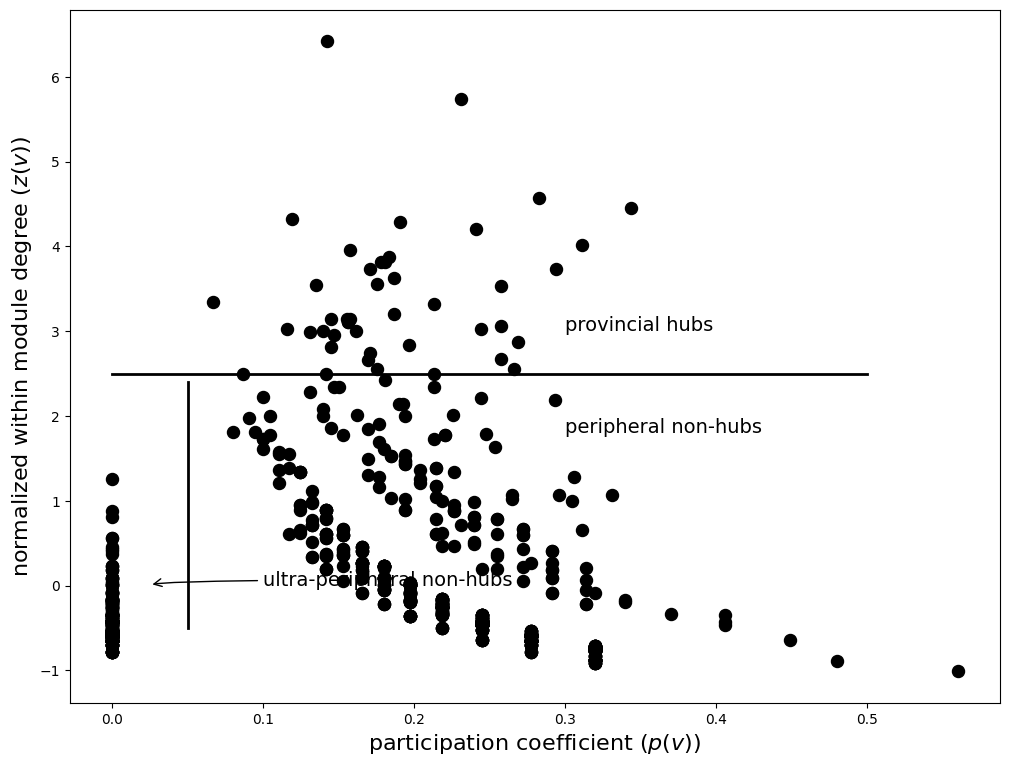

In [41]:
# compute z(v) and p(v) scores for all nodes
G.vs['z'] = nwmd(G, G.vs['ground_truth_community'])
G.vs['p'] = pc(G, G.vs['ground_truth_community'])

# create the (z(v), p(v)) plot
fig, ax = plt.subplots(figsize=(12,9))

# plot all nodes
ax.scatter(G.vs['p'], G.vs['z'], marker='o', s=75, color='k')

# Add threshold lines (matching Karate club style)
plt.plot([0, .5], [2.5, 2.5], color='k', linestyle='-', linewidth=2)  # hub threshold
plt.plot([.05, .05], [-.5, 2.4], color='k', linestyle='-', linewidth=2)  # ultra-peripheral threshold

# Add labels
plt.xlabel(r'participation coefficient ($p(v)$)', fontsize=16)
plt.ylabel(r'normalized within module degree ($z(v)$)', fontsize=16)

# Add role labels
ax.annotate('ultra-peripheral non-hubs', (0.025, 0.0), xytext=(.1, 0), 
            fontsize=14, arrowprops=dict(arrowstyle="->", connectionstyle="angle3,angleA=0,angleB=-90"))
ax.annotate('peripheral non-hubs', (0.3, 1.8), fontsize=14)
ax.annotate('provincial hubs', (0.3, 3.0), fontsize=14)

plt.show()

### Chapter 5 Question 6

Function that takes an array of integers representing the number of nodes, and returns a dataframe representing the algorithm execution times for each number of nodes:

In [35]:
import time


def compare_clustering_times(node_sizes, xi=0.1, gamma=2.5, delta=5, Delta=50, beta=1.5, s=50, S=100):
    algorithms = {
        'CNM': lambda g: g.community_fastgreedy().as_clustering().membership,
        'Louvain': lambda g: g.community_multilevel().membership,
        'Leiden': lambda g: g.community_leiden(objective_function='modularity').membership,
        'ECG': lambda g: g.community_ecg().membership,
        'Infomap': lambda g: g.community_infomap().membership,
        'Label Propagation': lambda g: g.community_label_propagation().membership,
        'Girvan-Newman': lambda g: g.community_edge_betweenness().as_clustering().membership
    }

    results = {algo: [] for algo in algorithms.keys()}

    for n in node_sizes:
        print(f"Processing graph with {n} nodes...")
        
        # generate the graph for the given n
        params = ABCDParams(vcount=n, gamma=gamma, min_degree=delta, max_degree=Delta, 
                          beta=beta, min_community_size=s, max_community_size=S, xi=xi)
        g = ABCDGraph(params).build()
        G = g.exporter.to_igraph()
        
        # run each algorithm and measure time
        for name, func in algorithms.items():
            start_time = time.time()
            partition = func(G)
            results[name].append(time.time() - start_time)

    df = pd.DataFrame(results, index=node_sizes).T
    # rename columns to show number of nodes
    df.columns = [f'n={n}' for n in node_sizes]
    return df

Let's run all of the other algorithms for n up to 1600:

In [42]:
node_sizes = [100, 200, 400, 800, 1600]
results_df = compare_clustering_times(node_sizes)
results_df

Processing graph with 100 nodes...
Processing graph with 200 nodes...
Processing graph with 400 nodes...
Processing graph with 800 nodes...
Processing graph with 1600 nodes...


,n=100,n=200,n=400,n=800,n=1600
CNM,0.001089,0.000611,0.001239,0.002806,0.005662
Louvain,0.000389,0.000260,0.000490,0.000967,0.002532
Leiden,0.000356,0.000323,0.000605,0.001214,0.002846
ECG,0.017177,0.013530,0.027139,0.053299,0.114246
Infomap,0.004945,0.013583,0.015948,0.035921,0.072595
Label Propagation,0.000085,0.000158,0.000225,0.000840,0.001082
Girvan-Newman,0.102090,0.523559,3.122819,23.452408,154.335264


As we can see, Girvan-Newman is by far the slowest algorithm, with Label Propagation being consistently the fastest.